# BESS Dispatch Optimizer — Module 3: Reporting
Generates the full P&L dashboard from optimizer output.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

from data_fetch import generate_mock_lmp, load_lmp
from optimizer import BatteryConfig, solve_rolling
from reporting import (
    build_dashboard,
    figure_dispatch,
    figure_pnl,
    figure_price_vs_dispatch,
    figure_stats_table,
)
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.dpi'] = 120

DB    = 'bess_lmp.db'
NODE  = 'CAPITL'
START = '2025-01-01'
END   = '2025-01-14'
print('Imports OK')

Imports OK


In [2]:
# ── 1. Generate data & optimise ───────────────────────────────────────────
generate_mock_lmp(START, END, node=NODE, db_path=DB, seed=42)
lmp = load_lmp(START, END, node=NODE, db_path=DB)

cfg = BatteryConfig(
    power_mw     = 10.0,
    energy_mwh   = 40.0,
    rte          = 0.85,
    soc_min_frac = 0.10,
    soc_max_frac = 0.90,
)
result = solve_rolling(lmp, cfg)
print(result.summary())

Status          : Optimal
Total revenue   : $20,515.36
Charge total    : 895.3 MWh
Discharge total : 775.8 MWh
Equiv. cycles   : 19.39
Hours optimised : 336


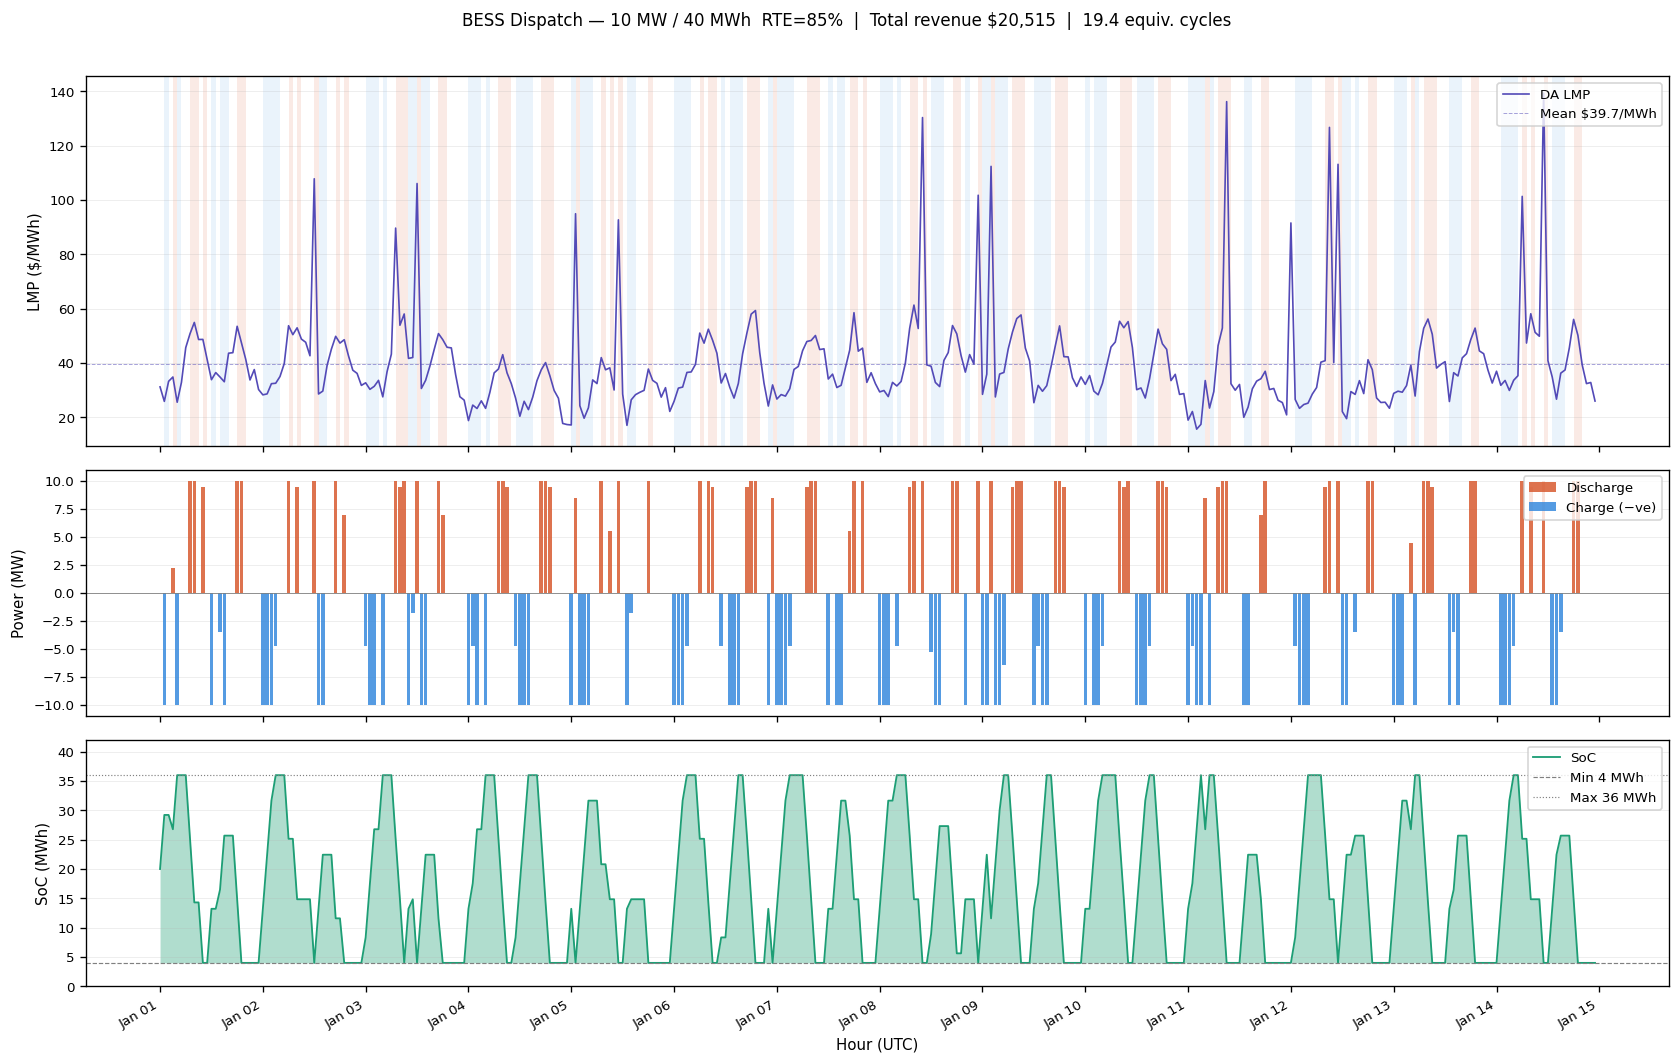

In [3]:
# ── 2. Figure 1 — dispatch overview ──────────────────────────────────────
fig1 = figure_dispatch(result)
plt.show()

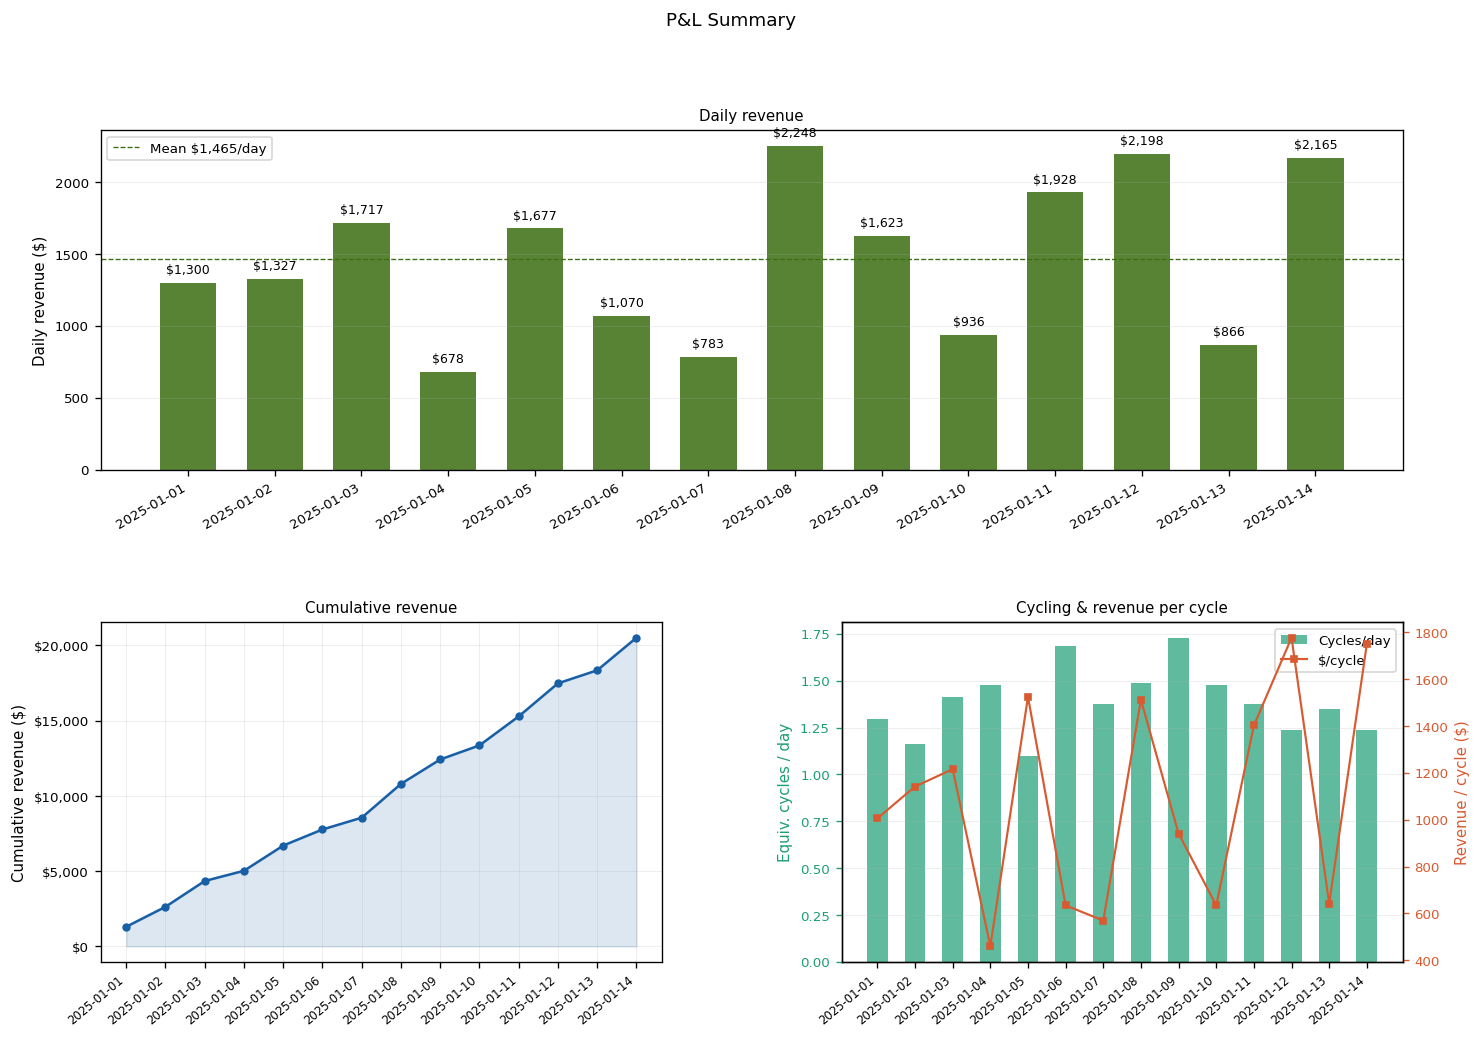

In [4]:
# ── 3. Figure 2 — P&L summary ────────────────────────────────────────────
fig2 = figure_pnl(result)
plt.show()

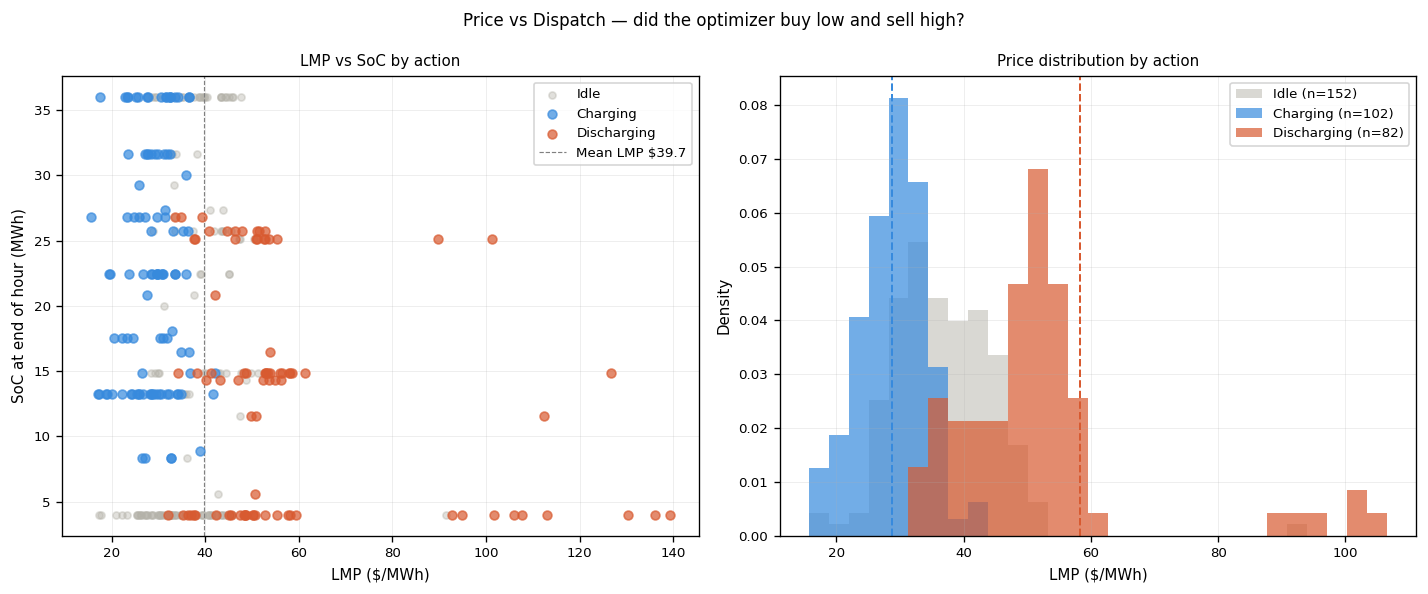

In [5]:
# ── 4. Figure 3 — price vs dispatch scatter ───────────────────────────────
fig3 = figure_price_vs_dispatch(result)
plt.show()

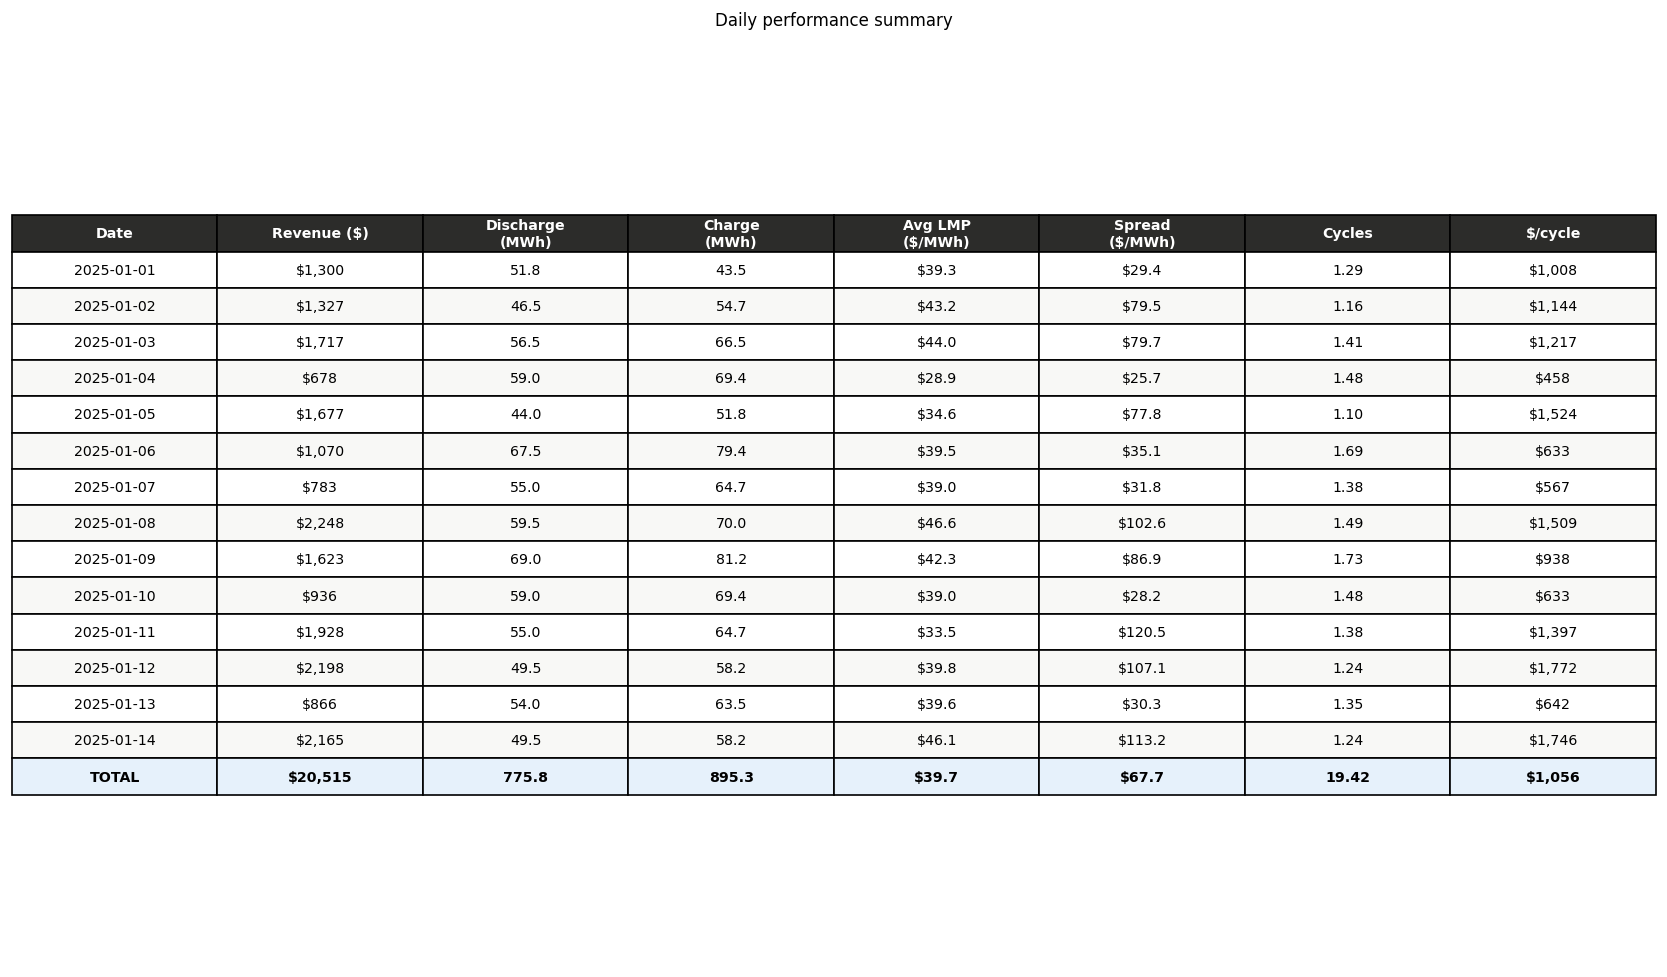

In [6]:
# ── 5. Figure 4 — stats table ─────────────────────────────────────────────
fig4 = figure_stats_table(result)
plt.show()

Charts saved to ./charts/


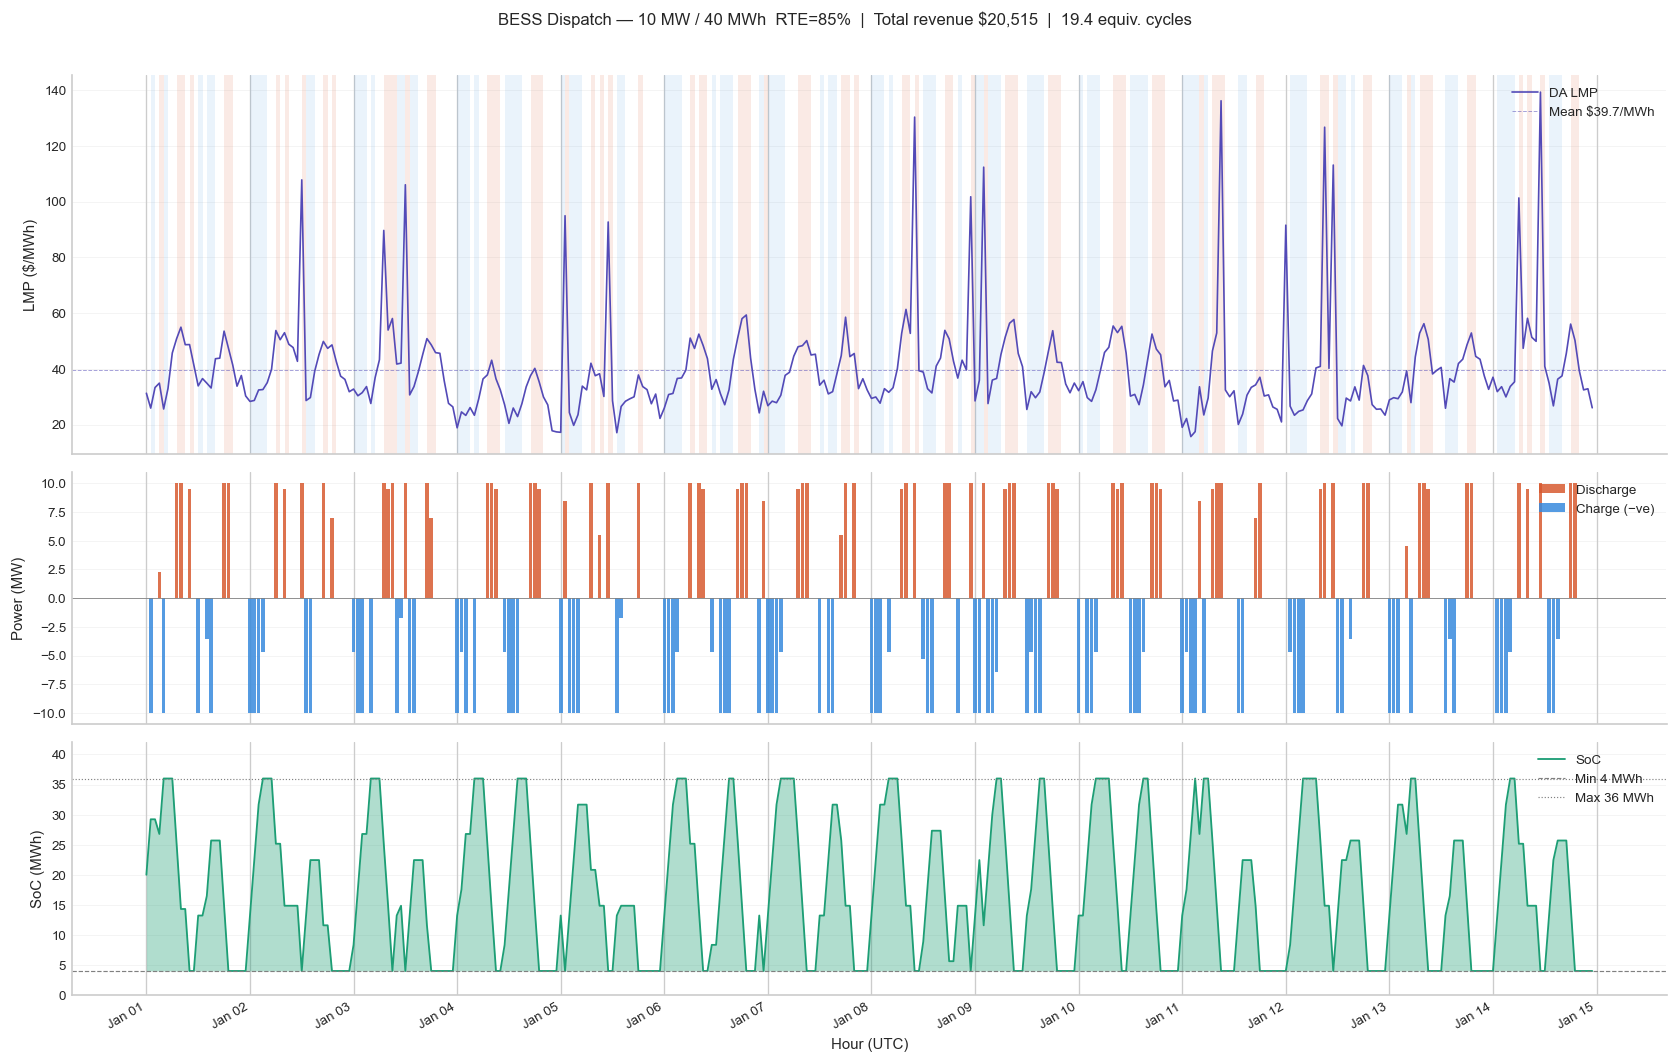

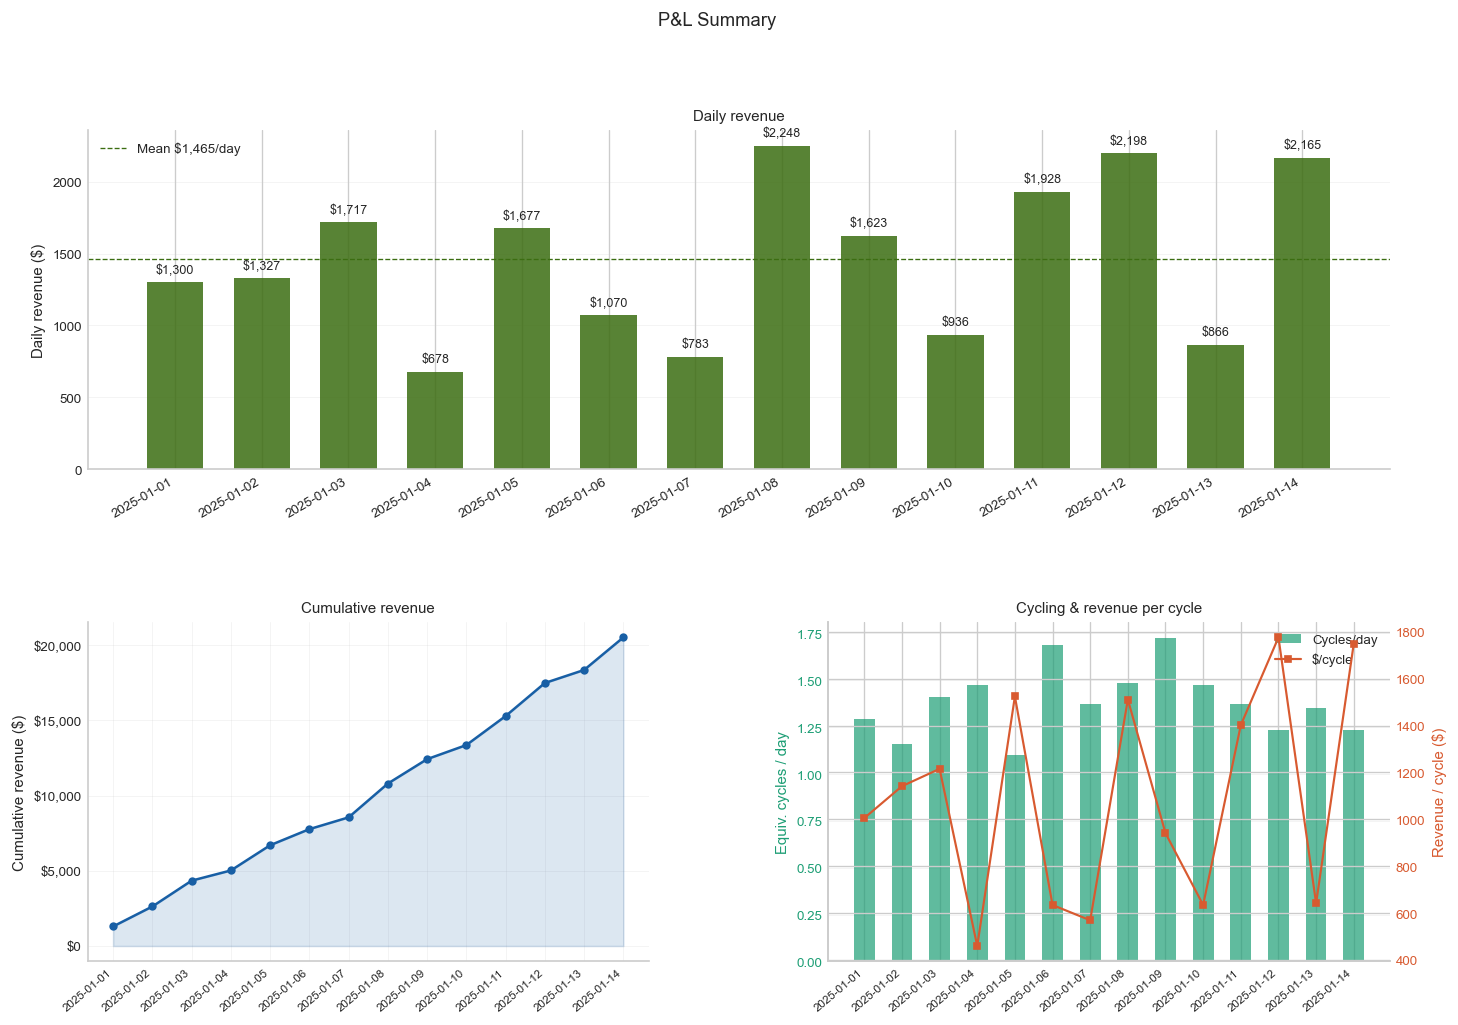

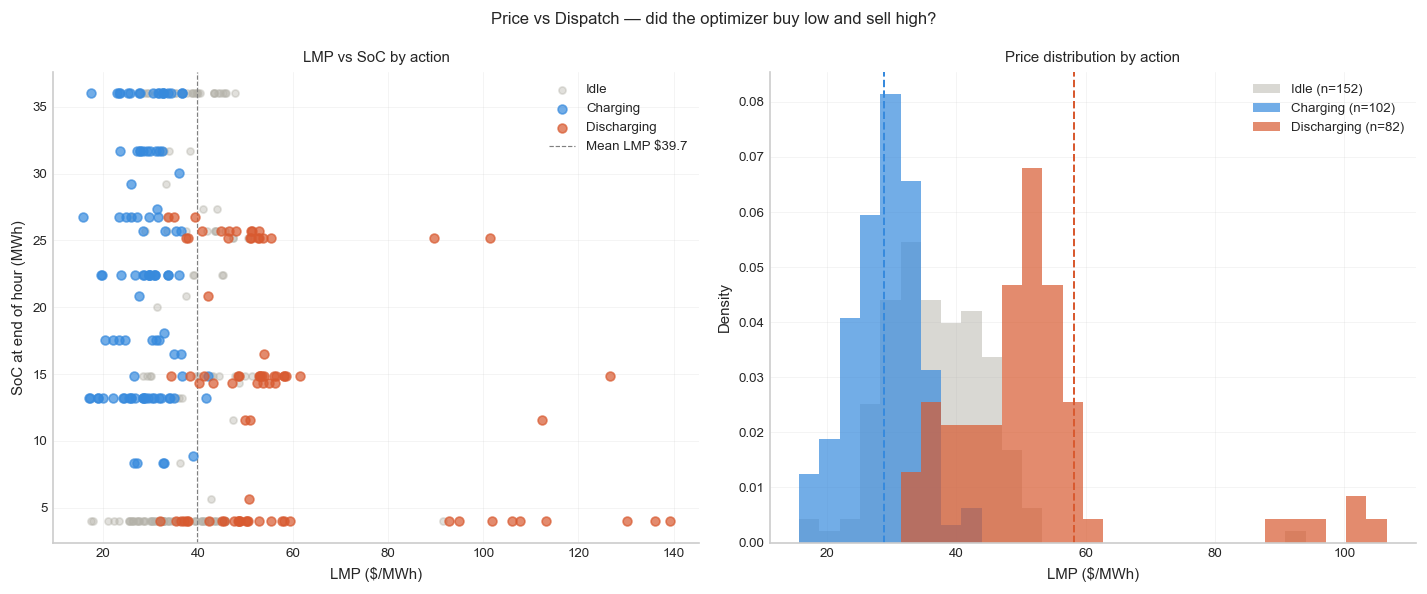

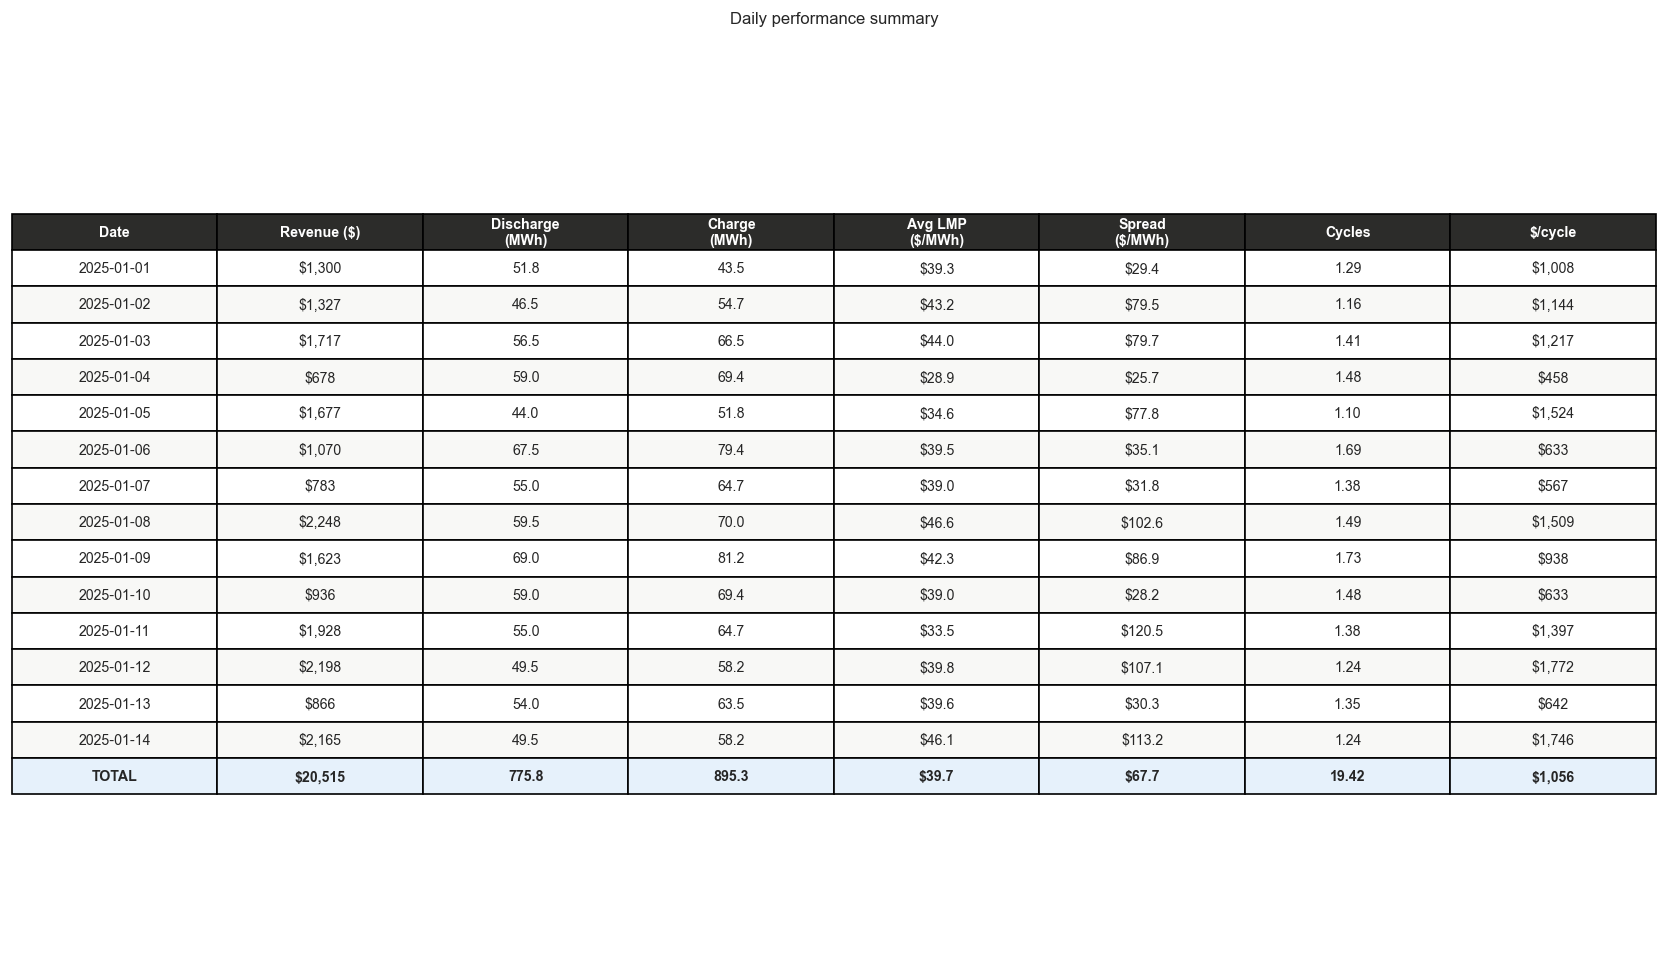

In [7]:
# ── 6. Save all charts to disk ────────────────────────────────────────────
from pathlib import Path
build_dashboard(result, save_dir=Path('charts'), show=False)
print('Charts saved to ./charts/')